In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px, plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display

pd.options.display.float_format = '{:,.2f}'.format
sns.set_style('whitegrid')

In [2]:
from google.colab import drive
# Mount drive to the standard local directory
drive.mount('/content/drive')

Mounted at /content/drive


#1. Memuat Data dan Memahami Struktur (untuk Problem Statement)

In [3]:
# Load dataset from Google Drive path after successful mount
df = pd.read_csv('/content/drive/MyDrive/DABI 23/Take Home Test/events.csv')
print(df.shape)
df.info()
df.head()

(885129, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 885129 entries, 0 to 885128
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   event_time     885129 non-null  object 
 1   event_type     885129 non-null  object 
 2   product_id     885129 non-null  int64  
 3   category_id    885129 non-null  int64  
 4   category_code  648910 non-null  object 
 5   brand          672765 non-null  object 
 6   price          885129 non-null  float64
 7   user_id        885129 non-null  int64  
 8   user_session   884964 non-null  object 
dtypes: float64(1), int64(3), object(5)
memory usage: 60.8+ MB


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2020-09-24 11:57:06 UTC,view,1996170,2144415922528452715,electronics.telephone,NaN,31.90,1515915625519388267,LJuJVLEjPT
1,2020-09-24 11:57:26 UTC,view,139905,2144415926932472027,computers.components.cooler,zalman,17.16,1515915625519380411,tdicluNnRY
2,2020-09-24 11:57:27 UTC,view,215454,2144415927158964449,NaN,NaN,9.81,1515915625513238515,4TMArHtXQy
3,2020-09-24 11:57:33 UTC,view,635807,2144415923107266682,computers.peripherals.printer,pantum,113.81,1515915625519014356,aGFYrNgC08
4,2020-09-24 11:57:36 UTC,view,3658723,2144415921169498184,NaN,cameronsino,15.87,1515915625510743344,aa4mmk0kwQ


In [4]:
print(df.event_type.value_counts())


event_type
view        793748
cart         54035
purchase     37346
Name: count, dtype: int64


##Missing Value

In [5]:
print(df.isna().sum())

event_time            0
event_type            0
product_id            0
category_id           0
category_code    236219
brand            212364
price                 0
user_id               0
user_session        165
dtype: int64


##Duplicate

In [6]:
print('Duplikat:', df.duplicated().sum())

Duplikat: 655


##Unique User & Product

In [7]:
print('User unik:', df.user_id.nunique(), '| Produk unik:', df.product_id.nunique())

User unik: 407283 | Produk unik: 53453


In [8]:
print(df.price.describe())

count   885,129.00
mean        146.33
std         296.81
min           0.22
25%          26.46
50%          65.71
75%         190.49
max      64,771.06
Name: price, dtype: float64


In [9]:
ev = df.event_type.value_counts()
print('View -> Cart    :', ev['cart']/ev['view'])
print('Cart -> Purchase:', ev['purchase']/ev['cart'])
print('View -> Purchase:', ev['purchase']/ev['view'])
buyers = df[df.event_type=='purchase'].user_id.nunique()
print('Persen user yang membeli:', buyers/df.user_id.nunique())

View -> Cart    : 0.06807576208066037
Cart -> Purchase: 0.6911446284815398
View -> Purchase: 0.047050197291835696
Persen user yang membeli: 0.05230760920539281


#Problem Statement

Toko online ini menarik traffic pengunjung yang besar, tetapi hanya 5,23% pengguna unik yang akhirnya melakukan pembelian, dan hanya 4,71% aktivitas melihat produk yang berujung transaksi. Funnel menunjukkan bahwa kebocoran terbesar terjadi di tahap awal. Hanya 6,81% aktivitas view yang berlanjut ke cart, padahal 69,11% cart berhasil menjadi pembelian. Artinya, pengunjung yang sudah memasukkan produk ke keranjang cenderung serius membeli, tetapi sebagian besar pengunjung tidak tertarik atau tidak yakin untuk melangkah sampai ke keranjang.

##Tujuan Analisis

Perlu dianalisis perilaku pengguna di sepanjang funnel (view, cart, purchase) untuk mengidentifikasi di mana dan mengapa pengguna berhenti, kategori, brand, dan waktu mana yang konversinya tinggi atau rendah, serta langkah apa yang paling efektif untuk meningkatkan konversi dan pendapatan

##Business Question

1. Di tahap mana funnel conversion drop, dan kategori mana yang konversinya paling lemah?
2. Bagaimana harga memengaruhi keputusan pengguna, baik untuk memasukkan produk ke keranjang maupun untuk membeli?
3. Kapan (jam dan bulan) konversi paling tinggi dan paling rendah, dan bagaimana tren konversinya?
4. Brand mana yang paling efektif mengubah view menjadi pembelian, dan brand mana yang trafiknya tinggi tetapi konversinya rendah?

#2. Data Preprocessing

In [10]:
n0 = len(df)
# 1) Hapus Duplicate

df = df.drop_duplicates()

df.duplicated().sum()

np.int64(0)

In [11]:
# 2) Konversi waktu (data dalam UTC)
df['event_time'] = pd.to_datetime(df['event_time'], utc=True)

In [12]:
# 3) Tangani missing values
df = df.dropna(subset=['user_session'])            # hanya 165 baris
df['category_code'] = df['category_code'].fillna('unknown')
df['brand'] = df['brand'].fillna('unknown')

In [13]:
# 4) Pecah kategori bertingkat
cat = df['category_code'].str.split('.', expand=True)
df['cat1'] = cat[0]
df['cat2'] = cat[1] if 1 in cat.columns else np.nan
df['cat3'] = cat[2] if 2 in cat.columns else np.nan

In [14]:
# 5) Fitur waktu
df['date']  = df['event_time'].dt.date
df['month'] = df['event_time'].dt.to_period('M').astype(str)
df['hour']  = df['event_time'].dt.hour
df['dow']   = df['event_time'].dt.day_name()

/tmp/ipykernel_2992/3976558470.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['month'] = df['event_time'].dt.to_period('M').astype(str)


In [15]:
# 6) ID sebagai string
for c in ['product_id','category_id','user_id']:
    df[c] = df[c].astype(str)

In [16]:
# 7) Outlier harga: tandai, jangan langsung dibuang
q999 = df['price'].quantile(0.999)
df['is_outlier_price'] = df['price'] > q999

print(f'Baris sebelum: {n0:,} | sesudah: {len(df):,}')

Baris sebelum: 885,129 | sesudah: 884,312


In [17]:
# 8) Save data to drive
df.to_csv('/content/drive/MyDrive/DABI 23/Take Home Test/events_update.csv', index=False)


#3. Exploratory Data Analysis

##Business Question 1



In [18]:
funnel = df.groupby('event_type').user_id.nunique().reindex(['view','cart','purchase'])
fig = go.Figure(go.Funnel(y=funnel.index, x=funnel.values, textinfo='value+percent initial'))
fig.update_layout(title='Funnel Pengguna Unik')
fig.show()

In [19]:
pv = df.pivot_table(index='cat1', columns='event_type', values='user_id',
                    aggfunc='count', fill_value=0)
pv['view_to_cart'] = pv['cart']/pv['view']
pv['cart_to_purchase'] = pv['purchase']/pv['cart']
pv['view_to_purchase'] = pv['purchase']/pv['view']
pv.sort_values('view', ascending=False).head(10)

event_type,cart,purchase,view,view_to_cart,cart_to_purchase,view_to_purchase
cat1,,,,,,
computers,26982,16870,272808,0.10,0.63,0.06
unknown,10407,7566,218028,0.05,0.73,0.03
electronics,9056,6768,155125,0.06,0.75,0.04
appliances,1205,904,38938,0.03,0.75,0.02
stationery,3233,2919,36796,0.09,0.90,0.08
auto,1459,1091,32858,0.04,0.75,0.03
construction,1362,999,28674,0.05,0.73,0.03
furniture,156,115,3093,0.05,0.74,0.04
country_yard,42,23,3072,0.01,0.55,0.01


###Insight:
Funnel paling bocor di tahap view ke keranjang, karena dari 406,82 ribu pengguna yang melihat produk hanya 36,95 ribu (9,1%) yang menambah ke keranjang dan 21,30 ribu (5,2%) yang akhirnya membeli, dengan konversi view-to-cart terlemah pada kategori construction (4,75%), furniture (5,04%), dan electronics (5,84%), jauh di bawah computers (9,89%) dan stationery (8,79%).

##Business Question 2

In [20]:
from plotly.subplots import make_subplots

ev = df.event_type.value_counts()

# Bucket harga (quintile), batasnya sekitar 21 / 47 / 96 / 227
df['price_bucket'] = pd.qcut(df.price, 5,
    labels=['1 Sangat murah (<21)','2 Murah (21-47)','3 Menengah (47-96)',
            '4 Mahal (96-227)','5 Sangat mahal (>227)'])

def rate(d, by):
    p = d.pivot_table(index=by, columns='event_type', values='user_id',
                      aggfunc='count', fill_value=0, observed=True)
    p['v2c'] = p['cart']/p['view']
    p['c2p'] = p['purchase']/p['cart']
    p['v2p'] = p['purchase']/p['view']
    return p

In [21]:
# Chart : per rentang harga (view→cart dan cart→purchase)
p = rate(df, 'price_bucket')
fig = make_subplots(rows=1, cols=2, subplot_titles=('View → Cart','Cart → Purchase'))
fig.add_trace(go.Bar(x=p.index.astype(str), y=p.v2c, text=p.v2c.map('{:.1%}'.format)), 1, 1)
fig.add_trace(go.Bar(x=p.index.astype(str), y=p.c2p, text=p.c2p.map('{:.1%}'.format)), 1, 2)
fig.update_layout(title='Konversi per Rentang Harga', showlegend=False)
fig.show()

###Insight:
Semakin mahal produk, semakin sering dimasukkan ke keranjang (view-to-cart naik dari 5,75% menjadi 8,63%), tetapi semakin jarang dibeli (cart-to-purchase turun dari 81,03% pada rentang 21–47 menjadi 55,63% pada produk di atas 227), sehingga hambatan produk mahal ada pada keputusan akhir, bukan pada minat.

##Business Question 3

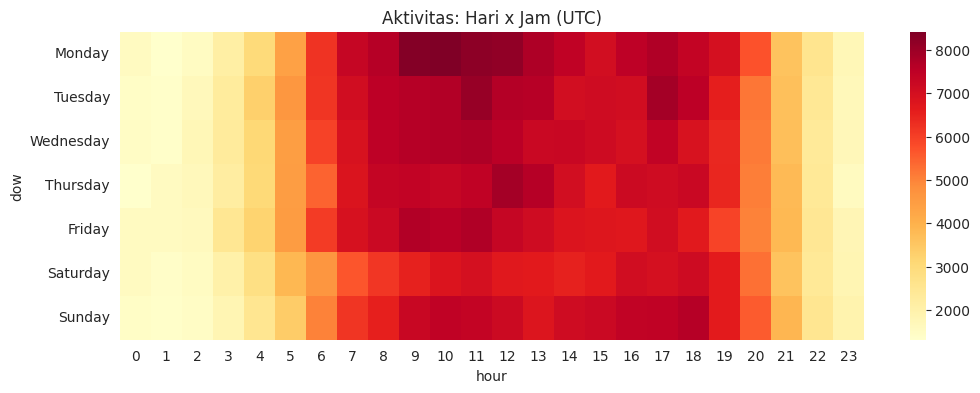

In [22]:
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
heat = df.pivot_table(index='dow', columns='hour', values='user_id', aggfunc='count').reindex(order)
plt.figure(figsize=(12,4)); sns.heatmap(heat, cmap='YlOrRd'); plt.title('Aktivitas: Hari x Jam (UTC)'); plt.show()

In [23]:
# Chart 1: trafik vs konversi per jam (waktu UTC)
h = rate(df, 'hour')
fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Bar(x=h.index, y=h.view, name='Jumlah view', opacity=.5), secondary_y=False)
fig.add_trace(go.Scatter(x=h.index, y=h.v2p, name='Konversi view→purchase', mode='lines+markers'), secondary_y=True)
fig.update_layout(title='Trafik vs Konversi per Jam (UTC)', xaxis_title='Jam')
fig.update_yaxes(tickformat='.1%', secondary_y=True)
fig.show()

In [24]:
# Chart 3: tren konversi per bulan (September 2020 parsial)
mo = rate(df, 'month')
fig = px.line(mo, x=mo.index, y='v2p', markers=True, title='Tren Konversi per Bulan')
fig.update_layout(yaxis_tickformat='.1%', xaxis_title='')
fig.show()

###Insight:
Konversi view-to-purchase memuncak di sekitar pukul 10.00 UTC (5,38%) dan terendah pada dini hari pukul 01.00 UTC (3,61%), sementara tren bulanannya naik stabil dari 4,29% pada Oktober 2020 menjadi 5,17% pada Februari 2021.

##Business Question 4

In [26]:
# Chart 3: brand dengan v2c tertinggi dan terendah (≥3.000 view)
b = rate(df[df.brand != 'unknown'], 'brand'); b = b[b.view >= 3000].sort_values('v2c')
bb = pd.concat([b.head(8), b.tail(8)])

# Calculate avg_v2c to prevent NameError
e_counts = df.event_type.value_counts()
avg_v2c = e_counts['cart'] / e_counts['view']

fig = px.bar(bb, x='v2c', y=bb.index, orientation='h', text=bb.v2c.map('{:.1%}'.format),
             title='Brand dengan View → Cart Terendah dan Tertinggi')
fig.add_vline(x=avg_v2c, line_dash='dash')
fig.update_layout(xaxis_tickformat='.0%', yaxis_title='')
fig.show()

###Insight:
Sapphire (v2p 11,44%), msi (8,97%), dan gigabyte (7,65%) paling efektif mengubah view menjadi pembelian, dengan msi juga menghasilkan revenue tertinggi (sekitar 643 ribu), sedangkan asus (24 ribu view, v2p 5,20%) dan palit (21 ribu view, v2p 5,02%, cart-to-purchase hanya 48,06%) memiliki trafik tinggi tetapi konversi yang rendah.

##Recommendations and Actionable Insights
1. Perbaiki halaman produk di kategori konversi rendah (construction, furniture, electronics) agar view ke cart naik dari 6,8% menjadi 7,5%, setara sekitar 5.500 keranjang tambahan.
2. Beri cicilan, garansi, gratis ongkir, dan pengingat keranjang untuk produk mahal agar cart ke purchase rentang termahal naik dari 56% menjadi 65%.
3. Pusatkan promosi pada pukul 09.00 sampai 11.00 UTC dan gunakan promo berbatas waktu di sore hari agar anggaran jatuh pada jam konversi tertinggi.
4. Jaga stok dan harga sapphire, msi, dan gigabyte, serta selidiki dan perbaiki konversi palit dan asus yang trafiknya tinggi tetapi konversinya rendah.
5. Wajibkan pengisian brand dan kategori produk agar analisis dan rekomendasi produk lebih akurat.

Bagaimana Rekomendasi Ini Membantu Bisnis?

Pendapatan toko dapat naik tanpa menambah biaya akuisisi trafik, karena rekomendasi ini bekerja pada pengunjung yang sudah datang. Sebagai gambaran, rata-rata nilai pembelian sekitar 137, sehingga setiap 1.000 pembelian tambahan setara sekitar 137 ribu revenue. Dari sisi strategis, rekomendasi 1 dan 2 menutup dua titik kebocoran terbesar di funnel, rekomendasi 3 dan 4 mengarahkan anggaran ke waktu dan brand yang paling menguntungkan, dan rekomendasi 5 memperkuat fondasi data untuk keputusan berikutnya.